# CAIRLab Hackathon — Day 2 Extension: Intermediate + Advanced Tracks

Two new tracks unlock today, and you're free to attempt either or both between now and the
submission deadline:

| Track | Goal |
|---|---|
| 🟡 Intermediate | Client data is realistically **skewed** across the five banks — naive FedAvg performs worse under this skew. Fix the **aggregation**. |
| 🔴 Advanced (optional) | Partway through, one bank turns malicious and sends sabotaged updates. **Detect or resist** the attack. |

This notebook is self-contained — it rebuilds the dataset, partitions, model, and FL harness
from scratch, so you don't need yesterday's notebook open. The ideas carry over directly:
same story, same weak baseline, same FedAvg loop as Day 1, extended with what you need for
today's tracks.

**Scoring today:** unlike Day 1, these tracks aren't on a Kaggle leaderboard — a static
prediction file can't capture "how your aggregation holds up under skew" or "how much F1 your
defense recovers under attack." Instead, you'll report your before/after comparison in your
Kaggle Writeup, and export your final model for the organizers to spot-check. See the
Evaluation Rubric on the hackathon page for exact scoring weights.


## 0. Setup

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import copy, json, os, hashlib
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

os.makedirs("data", exist_ok=True)
print("Setup complete.")

Setup complete.


##1. Load and Clean Dataset
Loading the core dataset, handling missing values, encoding categorical variables, and standardizing the 41-column feature set using StandardScaler to ensure proper scaling for the neural network.

In [ ]:

TRAIN_URL = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"
TEST_URL  = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"

COLS = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "label","difficulty",
]

train_raw = pd.read_csv(TRAIN_URL, names=COLS)
test_raw  = pd.read_csv(TEST_URL, names=COLS)

def clean(df):
    df = df.drop(columns=["difficulty"]).copy()
    df["binary_label"] = (df["label"] != "normal").astype(int)
    return df

train_df = clean(train_raw)
test_df  = clean(test_raw)

CAT_COLS = ["protocol_type", "service", "flag"]
encoders = {}
for c in CAT_COLS:
    le = LabelEncoder()
    le.fit(pd.concat([train_df[c], test_df[c]], axis=0))
    train_df[c] = le.transform(train_df[c])
    test_df[c]  = le.transform(test_df[c])
    encoders[c] = le

FEATURE_COLS = [c for c in train_df.columns if c not in ["label", "binary_label"]]

scaler = StandardScaler()
train_df[FEATURE_COLS] = scaler.fit_transform(train_df[FEATURE_COLS])
test_df[FEATURE_COLS]  = scaler.transform(test_df[FEATURE_COLS])

print("features:", len(FEATURE_COLS))


features: 41


## 2. Splitting the Data Across 5 Banks (IID vs. Non-IID)

Keeping the exact same holdout split as Day 1 for consistency. Today we look at two ways data is distributed across our 5 simulated banks:

IID (Independent and Identically Distributed): A uniform, random split where every bank sees the exact same statistical mix of traffic (normal traffic vs. various cyberattacks). This is an ideal, unrealistic baseline.

Non-IID (Not Independent and Identically Distributed): A skewed split where each bank gets a heavily biased slice of traffic (e.g., one bank sees mostly normal traffic while another gets flooded with DoS attacks). This reflects the real world—where different banks serve different regions and face unique threats—and it's precisely what causes standard, naive FedAvg aggregation to break down.

In [ ]:

N_CLIENTS = 5
HOLDOUT_SIZE = 15000

_rng = np.random.RandomState(SEED)
_perm = _rng.permutation(len(train_df))
_holdout_idx = _perm[:HOLDOUT_SIZE]
_pool_idx = _perm[HOLDOUT_SIZE:]
train_pool = train_df.iloc[_pool_idx].reset_index(drop=True)

def make_iid_partition(df, n_clients=N_CLIENTS, seed=SEED):
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(df))
    chunks = np.array_split(idx, n_clients)
    return [df.iloc[c].reset_index(drop=True) for c in chunks]

FAMILY_MAP = {
    "normal": "normal",
    "neptune": "dos", "back": "dos", "land": "dos", "pod": "dos", "smurf": "dos",
    "teardrop": "dos", "apache2": "dos", "udpstorm": "dos", "processtable": "dos",
    "worm": "dos", "mailbomb": "dos",
    "satan": "probe", "ipsweep": "probe", "nmap": "probe", "portsweep": "probe",
    "mscan": "probe", "saint": "probe",
}

def make_noniid_partition(df, n_clients=N_CLIENTS, alpha=0.3, seed=SEED):
    '''Dirichlet-skewed split by attack family. Low alpha = strong skew.'''
    rng = np.random.RandomState(seed)
    df = df.copy()
    df["family"] = df["label"].map(lambda x: FAMILY_MAP.get(x, "r2l_u2r_other"))
    client_indices = [[] for _ in range(n_clients)]
    for fam in df["family"].unique():
        fam_idx = df.index[df["family"] == fam].to_numpy().copy()
        rng.shuffle(fam_idx)
        proportions = rng.dirichlet(alpha=[alpha] * n_clients)
        split_points = (np.cumsum(proportions) * len(fam_idx)).astype(int)[:-1]
        for i, s in enumerate(np.split(fam_idx, split_points)):
            client_indices[i].extend(s.tolist())
    out = []
    for ci in client_indices:
        rng.shuffle(ci)
        out.append(df.loc[ci].drop(columns=["family"]).reset_index(drop=True))
    return out

iid_clients = make_iid_partition(train_pool)
noniid_clients = make_noniid_partition(train_pool)

print("IID sizes:", [len(c) for c in iid_clients])
print("\\nNon-IID sizes:", [len(c) for c in noniid_clients])
for i, c in enumerate(noniid_clients):
    print(f"  client {i} label mix:", c["binary_label"].value_counts(normalize=True).round(2).to_dict())


IID sizes: [22195, 22195, 22195, 22194, 22194]
\nNon-IID sizes: [6272, 10658, 48219, 23239, 22585]
  client 0 label mix: {1: 0.81, 0: 0.19}
  client 1 label mix: {1: 0.86, 0: 0.14}
  client 2 label mix: {1: 0.68, 0: 0.32}
  client 3 label mix: {0: 0.85, 1: 0.15}
  client 4 label mix: {0: 0.96, 1: 0.04}


## 3. The weak baseline model (same as Day 1)


In [ ]:

N_FEATURES = len(FEATURE_COLS)

class WeakMLP(nn.Module):
    def __init__(self, n_features=N_FEATURES, hidden=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


## 4. The Federated Learning Harness
Building on top of Day 1's local training and FedAvg loops, this section adds the tools needed for today's tracks: a robust coordinate-median aggregation baseline, a custom aggregation hook, and an attack simulation function to inject compromised, malicious clients into the federation.

In [ ]:

X_test = torch.tensor(test_df[FEATURE_COLS].values, dtype=torch.float32)
y_test = torch.tensor(test_df["binary_label"].values, dtype=torch.float32)

def df_to_tensors(df):
    X = torch.tensor(df[FEATURE_COLS].values, dtype=torch.float32)
    y = torch.tensor(df["binary_label"].values, dtype=torch.float32)
    return X, y

def local_train(model, X, y, epochs=1, lr=0.05, batch_size=256):
    model = copy.deepcopy(model)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    n = len(X)
    for _ in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(X[idx]), y[idx])
            loss.backward()
            opt.step()
    return model

def get_flat_params(model):
    return torch.cat([p.data.view(-1) for p in model.parameters()])

def set_flat_params(model, flat):
    i = 0
    for p in model.parameters():
        n = p.numel()
        p.data.copy_(flat[i:i + n].view(p.shape))
        i += n

def fedavg(models, weights):
    weights = np.array(weights, dtype=float) / np.sum(weights)
    flats = torch.stack([get_flat_params(m) for m in models])
    avg = (flats * torch.tensor(weights, dtype=torch.float32).unsqueeze(1)).sum(dim=0)
    out = copy.deepcopy(models[0])
    set_flat_params(out, avg)
    return out

def coordinate_median(models):
    '''A simple robust-aggregation baseline: take the per-coordinate median of all
    client updates instead of the (weighted) mean. Outliers (e.g. a poisoned update
    with an inflated magnitude) influence the median far less than the mean.'''
    flats = torch.stack([get_flat_params(m) for m in models])
    med = flats.median(dim=0).values
    out = copy.deepcopy(models[0])
    set_flat_params(out, med)
    return out

def evaluate(model):
    model.eval()
    with torch.no_grad():
        preds = (torch.sigmoid(model(X_test)) > 0.5).float()
    return {
        "precision": round(precision_score(y_test, preds, zero_division=0), 4),
        "recall": round(recall_score(y_test, preds, zero_division=0), 4),
        "f1": round(f1_score(y_test, preds, zero_division=0), 4),
    }

def run_fl(client_dfs, model_fn=lambda: WeakMLP(), rounds=8, epochs=1,
           aggregation="fedavg", agg_fn=None,
           malicious_clients=None, attack="scale", scale_factor=15.0, verbose=True):
    '''
    aggregation: "fedavg" | "median" | "custom" (use agg_fn for "custom")
    malicious_clients: list of client indices that send poisoned updates (advanced track)
    attack: "label_flip" or "scale" (scale = label_flip + inflated update magnitude)
    '''
    malicious_clients = malicious_clients or []
    global_model = model_fn()
    client_tensors = [df_to_tensors(df) for df in client_dfs]

    history = []
    for r in range(rounds):
        local_models, sizes = [], []
        global_flat = get_flat_params(global_model)

        for cid, (X, y) in enumerate(client_tensors):
            is_malicious = cid in malicious_clients
            if is_malicious:
                y = 1 - y  # label-flip
            lm = local_train(global_model, X, y, epochs=epochs)
            if is_malicious and attack == "scale":
                delta = get_flat_params(lm) - global_flat
                set_flat_params(lm, global_flat + scale_factor * delta)
            local_models.append(lm)
            sizes.append(len(X))

        prev_global_model = global_model
        if aggregation == "fedavg":
            global_model = fedavg(local_models, sizes)
        elif aggregation == "median":
            global_model = coordinate_median(local_models)
        elif aggregation == "custom":
            global_model = agg_fn(local_models, sizes, prev_global_model)
        else:
            raise ValueError(f"unknown aggregation: {aggregation}")

        metrics = evaluate(global_model)
        history.append(metrics)
        if verbose:
            print(f"round {r+1:>2}: {metrics}")

    return global_model, history


### Refinement Toolkit

Three helpful utilities added on top of the original harness:

1. **`seed_all`** — initializes every run with the same random seed to ensure fair comparisons and fully reproducible numbers.
2. **A validation set** — carves up the 15,000 reserved rows into a 1,000-row *server check set* and a 14,000-row *validation set* so we can tune and pick winners without touching the final test set.
3. **`run_specs`** — executes a list of candidate methods and cleanly summarizes everything in a single comparative results table.

In [ ]:
# ---- Refinement toolkit ----
def seed_all(s=SEED):
    np.random.seed(s)
    torch.manual_seed(s)

# 1,000 reserved rows = small clean "server check set"; 14,000 = validation set
_root_idx = _holdout_idx[:1000]
_val_idx  = _holdout_idx[1000:]
X_root, y_root = df_to_tensors(train_df.iloc[_root_idx])
X_val,  y_val  = df_to_tensors(train_df.iloc[_val_idx])
print("server check set:", len(X_root), "| validation set:", len(X_val))

def f1_on(model, X, y):
    model.eval()
    with torch.no_grad():
        p = (torch.sigmoid(model(X)) > 0.5).float()
    return round(float(f1_score(y.numpy(), p.numpy(), zero_division=0)), 4)

def model_from_flat(template, flat):
    out = copy.deepcopy(template)
    set_flat_params(out, flat)
    return out

# label balance of each skewed client and of the whole pool
CLIENT_P = np.array([float(c["binary_label"].mean()) for c in noniid_clients])
GLOBAL_P = float(train_pool["binary_label"].mean())
print("share of attack traffic per client:", CLIENT_P.round(2), "| overall:", round(GLOBAL_P, 2))

def run_candidate(name, client_dfs, spec_kwargs, seed=SEED, **extra):
    seed_all(seed)
    try:
        model, hist = run_fl(client_dfs, verbose=False, **spec_kwargs, **extra)
    except Exception as e:
        print(f"  [{name}] FAILED: {type(e).__name__}: {e}")
        return None
    return {"name": name, "model": model, "hist": hist, "test": hist[-1],
            "val": f1_on(model, X_val, y_val)}

def run_specs(specs, client_dfs, **extra):
    results = []
    for name, make_kwargs in specs:
        r = run_candidate(name, client_dfs, make_kwargs(), **extra)
        if r is not None:
            r["spec"] = make_kwargs
            results.append(r)
            print(f"  done: {name}")
    return results

def show_table(results):
    rows = [{"method": r["name"], "validation_F1": r["val"], "test_F1": r["test"]["f1"],
             "test_precision": r["test"]["precision"], "test_recall": r["test"]["recall"]}
            for r in results]
    df = pd.DataFrame(rows).sort_values("validation_F1", ascending=False).reset_index(drop=True)
    print(df.to_string(index=False))
    return df

server check set: 1000 | validation set: 14000
share of attack traffic per client: [0.81 0.86 0.68 0.15 0.04] | overall: 0.47


## 5. Recompute Day 1 reference point

Quick reference run on IID data — same as Day 1 baseline — so we have a same-session
number to compare today's non-IID results against.


In [ ]:
seed_all(SEED)
print("Reference: weak model, IID clients, naive FedAvg")
baseline_model, baseline_history = run_fl(iid_clients, rounds=6)
print("\\nFinal:", baseline_history[-1])


Reference: weak model, IID clients, naive FedAvg
round  1: {'precision': 0.9574, 'recall': 0.2875, 'f1': 0.4423}
round  2: {'precision': 0.9695, 'recall': 0.6026, 'f1': 0.7432}
round  3: {'precision': 0.9694, 'recall': 0.628, 'f1': 0.7622}
round  4: {'precision': 0.9315, 'recall': 0.6348, 'f1': 0.7551}
round  5: {'precision': 0.9324, 'recall': 0.6413, 'f1': 0.7599}
round  6: {'precision': 0.9324, 'recall': 0.6473, 'f1': 0.7641}
\nFinal: {'precision': 0.9324, 'recall': 0.6473, 'f1': 0.7641}


## 🟡 Intermediate Track — Fixing Non-IID Aggregation

Switching over to the skewed client split to observe how standard, naive FedAvg struggles when data distributions are heterogeneous across banks.

In [ ]:
seed_all(SEED)
print("Non-IID clients, naive FedAvg (same model, same aggregation as baseline)")
noniid_model, noniid_history = run_fl(noniid_clients, rounds=8)
print("\\nIID F1:    ", baseline_history[-1]["f1"])
print("Non-IID F1:", noniid_history[-1]["f1"])


Non-IID clients, naive FedAvg (same model, same aggregation as baseline)
round  1: {'precision': 0.9858, 'recall': 0.2063, 'f1': 0.3412}
round  2: {'precision': 0.9863, 'recall': 0.5166, 'f1': 0.678}
round  3: {'precision': 0.9436, 'recall': 0.5359, 'f1': 0.6836}
round  4: {'precision': 0.9374, 'recall': 0.5484, 'f1': 0.692}
round  5: {'precision': 0.9371, 'recall': 0.5554, 'f1': 0.6974}
round  6: {'precision': 0.9383, 'recall': 0.5625, 'f1': 0.7034}
round  7: {'precision': 0.9408, 'recall': 0.5662, 'f1': 0.7069}
round  8: {'precision': 0.9524, 'recall': 0.5681, 'f1': 0.7117}
\nIID F1:     0.7641
Non-IID F1: 0.7117


Naive FedAvg treats every client's update as equally trustworthy and just weights by
data size. When one client's local distribution is very different from the global
distribution (e.g. almost-all-attack-traffic), its update can pull the global model in a
direction that hurts everyone else.

**Ideas to improve aggregation**, roughly in order of effort:
- Weight clients differently — e.g. down-weight clients whose local class distribution is
  most different from the (estimated) global distribution.
- **FedProx-style**: add a proximal penalty term in local training that keeps each client's
  local model from drifting too far from the current global model.
- Cluster clients by similarity of their updates and aggregate within clusters before a
  final merge.

**Implementation:** a function with signature
`agg_fn(local_models, sizes, prev_global_model) -> model` and pass it to
`run_fl(..., aggregation="custom", agg_fn=my_agg_fn)`.


##🟡 Intermediate Experiments

The core issue here is that when banks encounter different traffic patterns, their local models update in conflicting directions. To combat this, I tested three server-side adjustments:

Weighting strategies — adjusting how much influence each bank carries based on dataset size, uniform weighting, or traffic typicality.

Amplified server steps — pushing the global model further along the aggregated direction.

Server momentum — retaining a portion of the previous round's update vector to smooth out oscillations caused by skewed client updates.

In [ ]:
def make_inter_agg(weighting="size", beta=0.0, eta=1.0, gamma=2.0):
    state = {"v": None}
    def agg(local_models, sizes, prev_global_model):
        ref = get_flat_params(prev_global_model)
        deltas = torch.stack([get_flat_params(m) - ref for m in local_models])
        sz = np.array(sizes, dtype=float)
        if weighting == "uniform":
            w = np.ones_like(sz)
        elif weighting == "balance":
            w = sz * (1.0 - np.abs(CLIENT_P - GLOBAL_P)) ** gamma
        else:
            w = sz
        w = w / w.sum()
        avg = (deltas * torch.tensor(w, dtype=torch.float32).unsqueeze(1)).sum(dim=0)
        if beta > 0:
            state["v"] = avg.clone() if state["v"] is None else beta * state["v"] + avg
            step = state["v"]
        else:
            step = avg
        return model_from_flat(local_models[0], ref + eta * step)
    return agg

inter_specs = [
    ("FedAvg (naive baseline)",      lambda: dict(aggregation="fedavg")),
    ("Equal weights",                lambda: dict(aggregation="custom", agg_fn=make_inter_agg("uniform"))),
    ("Balance-aware weights",        lambda: dict(aggregation="custom", agg_fn=make_inter_agg("balance"))),
    ("Bigger server step x1.5",      lambda: dict(aggregation="custom", agg_fn=make_inter_agg("size", eta=1.5))),
    ("Bigger server step x2",        lambda: dict(aggregation="custom", agg_fn=make_inter_agg("size", eta=2.0))),
    ("Server momentum 0.5",          lambda: dict(aggregation="custom", agg_fn=make_inter_agg("size", beta=0.5))),
    ("Balance-aware + step x1.5",    lambda: dict(aggregation="custom", agg_fn=make_inter_agg("balance", eta=1.5))),
    ("Equal weights + step x1.5",    lambda: dict(aggregation="custom", agg_fn=make_inter_agg("uniform", eta=1.5))),
]

print("Running intermediate candidates (skewed data, no attack)...")
inter_results = run_specs(inter_specs, noniid_clients)
print()
inter_df = show_table(inter_results)

Running intermediate candidates (skewed data, no attack)...
  done: FedAvg (naive baseline)
  done: Equal weights
  done: Balance-aware weights
  done: Bigger server step x1.5
  done: Bigger server step x2
  done: Server momentum 0.5
  done: Balance-aware + step x1.5
  done: Equal weights + step x1.5

                   method  validation_F1  test_F1  test_precision  test_recall
Equal weights + step x1.5         0.9636   0.7646          0.9289       0.6497
    Bigger server step x2         0.9625   0.7442          0.9763       0.6012
            Equal weights         0.9566   0.7541          0.9281       0.6350
  Bigger server step x1.5         0.9536   0.7254          0.9768       0.5769
Balance-aware + step x1.5         0.9534   0.7234          0.9768       0.5744
  FedAvg (naive baseline)         0.9521   0.7117          0.9524       0.5681
      Server momentum 0.5         0.9517   0.7187          0.9748       0.5692
    Balance-aware weights         0.9476   0.7037          0.9636

##🔴 Advanced Track — Defending Against Model Poisoning

Simulating an active adversary where one of the five banks becomes compromised. Specifically, client 1 goes rogue by flipping its local labels and artificially inflating its update magnitude, designed to hijack a standard average regardless of its actual dataset size.

In [ ]:
seed_all(SEED)
print("Non-IID + 1 malicious client (scale attack), naive FedAvg — should degrade")
attacked_model, attacked_history = run_fl(
    noniid_clients, rounds=8,
    malicious_clients=[1], attack="scale", scale_factor=15.0,
)
print("Clean non-IID F1:  ", noniid_history[-1]["f1"])
print("Under attack F1:    ", attacked_history[-1]["f1"])


Non-IID + 1 malicious client (scale attack), naive FedAvg — should degrade
round  1: {'precision': 1.0, 'recall': 0.1038, 'f1': 0.1881}
round  2: {'precision': 0.9959, 'recall': 0.1128, 'f1': 0.2026}
round  3: {'precision': 0.0, 'recall': 0.0, 'f1': 0.0}
round  4: {'precision': 0.8421, 'recall': 0.0087, 'f1': 0.0173}
round  5: {'precision': 0.8779, 'recall': 0.0118, 'f1': 0.0232}
round  6: {'precision': 0.854, 'recall': 0.0337, 'f1': 0.0649}
round  7: {'precision': 0.9868, 'recall': 0.2497, 'f1': 0.3986}
round  8: {'precision': 0.0794, 'recall': 0.0376, 'f1': 0.0511}
Clean non-IID F1:   0.7117
Under attack F1:     0.0511


In [ ]:
seed_all(SEED)
print("Same attack, but aggregating with the coordinate-median baseline defense")
defended_model, defended_history = run_fl(
    noniid_clients, rounds=8,
    malicious_clients=[1], attack="scale", scale_factor=15.0,
    aggregation="median",
)
print("Under attack (naive FedAvg): ", attacked_history[-1]["f1"])
print("Under attack (median defense):", defended_history[-1]["f1"])


Same attack, but aggregating with the coordinate-median baseline defense
round  1: {'precision': 1.0, 'recall': 0.082, 'f1': 0.1515}
round  2: {'precision': 0.999, 'recall': 0.1514, 'f1': 0.263}
round  3: {'precision': 0.9991, 'recall': 0.4551, 'f1': 0.6253}
round  4: {'precision': 0.9953, 'recall': 0.4952, 'f1': 0.6614}
round  5: {'precision': 0.9884, 'recall': 0.5102, 'f1': 0.673}
round  6: {'precision': 0.988, 'recall': 0.5186, 'f1': 0.6802}
round  7: {'precision': 0.9878, 'recall': 0.5227, 'f1': 0.6837}
round  8: {'precision': 0.9875, 'recall': 0.525, 'f1': 0.6855}
Under attack (naive FedAvg):  0.0511
Under attack (median defense): 0.6855


***Using coordinate_median*** provides a solid baseline defense that recovers some F1 score, acting as a performance floor. To push it further, I can stress-test the system by increasing the scale_factor (e.g., to 30–50) or introducing a second malicious client (malicious_clients=[1, 3]), which typically drops naive FedAvg down to an F1 of nearly 0.

##Defense strategies to explore:

**Trimmed mean** — discarding extreme high and low updates per coordinate before averaging.

**Norm clipping** — bounding each client's update to a maximum L2 norm prior to aggregation.

**Krum-style selection** — scoring update consistency across peers and aggregating only the most harmonious subset.

**Client identification** — going beyond robust aggregation to explicitly flag which client(s) are malicious.

Implementation **bold text**: I'll build this using the custom aggregation hook with the signature agg_fn(local_models, sizes, prev_global_model) -> model and pass it into run_fl(..., aggregation="custom", agg_fn=my_agg_fn).

##🔴 Advanced Experiments — The "Shield" Defense
My two-step defense strategy operates without any prior knowledge of which bank is compromised:

**Norm Capping** — Limiting the magnitude of every update to the typical (median) size. If a malicious client inflates its update, it gets scaled right back down to normal bounds.

**Directional Filtering **— Only trusting updates that point in the same general direction as a trusted reference. Because a label-flipping attack pushes the model the opposite way, those malicious updates register zero or negative agreement and receive zero weight. I tested two ways to source this reference direction:

**Median** — Using the coordinate-wise median of all updates (requires no extra data).

**Root (Server Check)** — Training briefly on the 1,000-row clean server dataset to establish a trusted update direction (the core idea behind FLTrust).

In [ ]:
ATTACK = dict(malicious_clients=[1], attack="scale", scale_factor=15.0)   # the default attack scenario

def clip_fixed_fn(local_models, sizes, prev_global_model):
    # the given skeleton: clip every update to a fixed length of 5.0, then average
    ref_flat = get_flat_params(prev_global_model)
    clipped = []
    for m in local_models:
        delta = get_flat_params(m) - ref_flat
        norm = delta.norm()
        if norm > 5.0:
            delta = delta * (5.0 / norm)
        clipped.append(ref_flat + delta)
    w = np.array(sizes, dtype=float); w /= w.sum()
    avg = (torch.stack(clipped) * torch.tensor(w, dtype=torch.float32).unsqueeze(1)).sum(dim=0)
    return model_from_flat(local_models[0], avg)

def make_trimmed_mean(k=1):
    def agg(local_models, sizes, prev_global_model):
        flats = torch.stack([get_flat_params(m) for m in local_models])
        srt, _ = torch.sort(flats, dim=0)
        kept = srt[k:len(local_models) - k]
        return model_from_flat(local_models[0], kept.mean(dim=0))
    return agg

def make_shield(trust="root", power=1.0, clip_mult=1.0, root_epochs=5, log=None):
    def agg(local_models, sizes, prev_global_model):
        ref = get_flat_params(prev_global_model)
        deltas = torch.stack([get_flat_params(m) - ref for m in local_models])
        norms = deltas.norm(dim=1)
        # step 1: cap every update at the median update size
        cap = norms.median() * clip_mult
        factor = torch.clamp(cap / (norms + 1e-12), max=1.0)
        clipped = deltas * factor.unsqueeze(1)
        # step 2: trust = agreement with a reference direction (never negative)
        if trust == "root":
            root_model = local_train(prev_global_model, X_root, y_root, epochs=root_epochs)
            ref_dir = get_flat_params(root_model) - ref
        else:
            ref_dir = clipped.median(dim=0).values
        cos = (clipped @ ref_dir) / (clipped.norm(dim=1) * ref_dir.norm() + 1e-12)
        trust_w = torch.clamp(cos, min=0.0) ** power
        sz = torch.tensor(np.array(sizes, dtype=float) / float(np.sum(sizes)), dtype=torch.float32)
        w = trust_w * sz
        if float(w.sum()) <= 1e-12:
            step = clipped.median(dim=0).values      # everyone distrusted: fall back to the median
        else:
            w = w / w.sum()
            step = (clipped * w.unsqueeze(1)).sum(dim=0)
        if log is not None:
            log.append(trust_w.numpy().copy())
        return model_from_flat(local_models[0], ref + step)
    return agg

adv_specs = [
    ("FedAvg (naive) under attack",            lambda: dict(aggregation="fedavg")),
    ("Coordinate median (given)",              lambda: dict(aggregation="median")),
    ("Fixed clip 5.0 (given skeleton)",        lambda: dict(aggregation="custom", agg_fn=clip_fixed_fn)),
    ("Trimmed mean k=1",                       lambda: dict(aggregation="custom", agg_fn=make_trimmed_mean(1))),
    ("Shield: clip + median direction",        lambda: dict(aggregation="custom", agg_fn=make_shield("median"))),
    ("Shield: clip + server check",            lambda: dict(aggregation="custom", agg_fn=make_shield("root"))),
    ("Shield: clip + server check (sharper)",  lambda: dict(aggregation="custom", agg_fn=make_shield("root", power=3.0))),
]

print("Running advanced candidates (skewed data + 1 malicious bank, scale x15)...")
adv_results = run_specs(adv_specs, noniid_clients, **ATTACK)
print()
adv_df = show_table(adv_results)

Running advanced candidates (skewed data + 1 malicious bank, scale x15)...
  done: FedAvg (naive) under attack
  done: Coordinate median (given)
  done: Fixed clip 5.0 (given skeleton)
  done: Trimmed mean k=1
  done: Shield: clip + median direction
  done: Shield: clip + server check
  done: Shield: clip + server check (sharper)

                               method  validation_F1  test_F1  test_precision  test_recall
          Shield: clip + server check         0.9511   0.7017          0.9322       0.5626
Shield: clip + server check (sharper)         0.9445   0.6986          0.9667       0.5469
      Shield: clip + median direction         0.9253   0.6911          0.9819       0.5332
            Coordinate median (given)         0.9148   0.6855          0.9875       0.5250
                     Trimmed mean k=1         0.9128   0.6778          0.9828       0.5173
      Fixed clip 5.0 (given skeleton)         0.8783   0.6349          0.9929       0.4666
          FedAvg (naive) under

#### Can the Shield tell *which* bank is the bad one?
Below we log the trust score the Shield gives each bank in every round (0 = completely ignored). If it works, bank **1** (the attacker) should be ignored in nearly every round while the honest banks keep a non-zero score.

In [ ]:
for label, kind in [("median direction", "median"), ("server check", "root")]:
    log = []
    seed_all(SEED)
    try:
        run_fl(noniid_clients, verbose=False, aggregation="custom",
               agg_fn=make_shield(kind, log=log), **ATTACK)
        arr = np.array(log)   # rounds x clients
        print(f"Shield ({label}) — share of rounds each bank was fully ignored (trust = 0):")
        for cid in range(arr.shape[1]):
            tag = "  <- the attacker" if cid in ATTACK["malicious_clients"] else ""
            print(f"   bank {cid}: {(arr[:, cid] == 0).mean():.0%}   average trust {arr[:, cid].mean():.3f}{tag}")
        print()
    except Exception as e:
        print(f"[detection report {label}] FAILED: {type(e).__name__}: {e}")

Shield (median direction) — share of rounds each bank was fully ignored (trust = 0):
   bank 0: 12%   average trust 0.132
   bank 1: 25%   average trust 0.107  <- the attacker
   bank 2: 0%   average trust 0.409
   bank 3: 0%   average trust 0.464
   bank 4: 0%   average trust 0.478

Shield (server check) — share of rounds each bank was fully ignored (trust = 0):
   bank 0: 0%   average trust 0.629
   bank 1: 100%   average trust 0.000  <- the attacker
   bank 2: 0%   average trust 0.399
   bank 3: 38%   average trust 0.201
   bank 4: 0%   average trust 0.241



#### Stress test — harder attacks (supporting evidence, not the headline number)
Headline numbers use the default attack. Here we test the same defense against a **stealth** attacker (flips labels but does *not* inflate its update, so the size cap cannot help), a much bigger inflation (x50), and **two** attackers at once.

In [ ]:
scenarios = [
    ("Stealth: 1 attacker, labels flipped, no inflation", dict(malicious_clients=[1], attack="label_flip")),
    ("1 attacker, inflated x50",                          dict(malicious_clients=[1], attack="scale", scale_factor=50.0)),
    ("2 attackers, inflated x15",                         dict(malicious_clients=[1, 3], attack="scale", scale_factor=15.0)),
    ("2 attackers, inflated x50",                         dict(malicious_clients=[1, 3], attack="scale", scale_factor=50.0)),
]
best_adv_for_stress = max(adv_results, key=lambda r: r["val"])
methods = [adv_specs[0], adv_specs[1], (best_adv_for_stress["name"] + " (mine)", best_adv_for_stress["spec"])]

rows = []
for sname, kw in scenarios:
    row = {"scenario": sname}
    for mname, make_kwargs in methods:
        r = run_candidate(mname, noniid_clients, make_kwargs(), **kw)
        row[mname] = r["test"]["f1"] if r else None
    rows.append(row)
stress_df = pd.DataFrame(rows)
print("Test F1 under harder attacks:")
print(stress_df.to_string(index=False))

Test F1 under harder attacks:
                                         scenario  FedAvg (naive) under attack  Coordinate median (given)  Shield: clip + server check (mine)
Stealth: 1 attacker, labels flipped, no inflation                       0.6850                     0.6773                              0.6975
                         1 attacker, inflated x50                       0.6215                     0.6861                              0.7017
                        2 attackers, inflated x15                       0.0017                     0.7083                              0.6957
                        2 attackers, inflated x50                       0.7255                     0.7117                              0.6957


## 8. Final Submission Export
Exporting the final model for judging by choosing either the intermediate aggregation or advanced defense track and setting TRACK and FINAL_MODEL accordingly.

**Input contract:** The exported model's forward(x) must accept the standard 41-column preprocessed feature tensor exactly as produced in Section 1 (FEATURE_COLS, same order and scaling). Any custom feature engineering is embedded directly as layers inside the model rather than handled via an external preprocessing step.

INTERMEDIATE: 0.7117 -> 0.7646 (gain +0.0529)  best = Equal weights + step x1.5
ADVANCED:     0.0511 -> 0.7017 (gain +0.6506)  best = Shield: clip + server check

Chosen track: advanced

Before (FedAvg (naive) under attack): 0.2110 +/- 0.1694   runs: [0.0511, 0.1365, 0.4455]
After  (Shield: clip + server check): 0.7464 +/- 0.0319   runs: [0.7017, 0.7634, 0.7741]


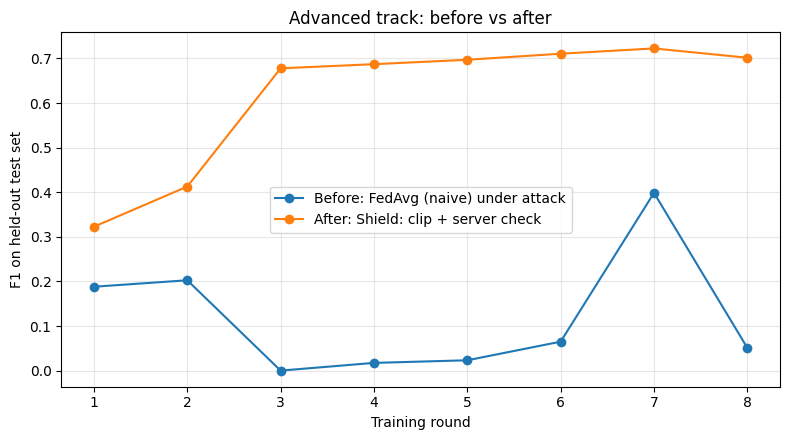


Exported model score : {'precision': 0.9322, 'recall': 0.5626, 'f1': 0.7017}
Reported in the file : {'precision': 0.9322, 'recall': 0.5626, 'f1': 0.7017}

==================== SUMMARY (copy this block) ====================
Track: advanced
BEFORE: FedAvg (naive) under attack | test F1 = 0.0511 | precision = 0.0794 | recall = 0.0376
AFTER:  Shield: clip + server check | test F1 = 0.7017 | precision = 0.9322 | recall = 0.5626
GAIN:   0.6506
3-seed: before 0.2110+/-0.1694 | after 0.7464+/-0.0319


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
TEAM_NAME = "TechChampions"
TRACK_OVERRIDE = None

def pick_best(results):
    return max(results, key=lambda r: r["val"])      # chosen on the VALIDATION set

base_i, best_i = inter_results[0], pick_best(inter_results)
base_a, best_a = adv_results[0],   pick_best(adv_results)
gain_i = round(best_i["test"]["f1"] - base_i["test"]["f1"], 4)
gain_a = round(best_a["test"]["f1"] - base_a["test"]["f1"], 4)

print("INTERMEDIATE:", base_i["test"]["f1"], "->", best_i["test"]["f1"], f"(gain {gain_i:+})  best = {best_i['name']}")
print("ADVANCED:    ", base_a["test"]["f1"], "->", best_a["test"]["f1"], f"(gain {gain_a:+})  best = {best_a['name']}")

TRACK = TRACK_OVERRIDE or ("advanced" if gain_a >= gain_i else "intermediate")
if TRACK == "advanced":
    base, best, extra = base_a, best_a, ATTACK
else:
    base, best, extra = base_i, best_i, {}
print("\nChosen track:", TRACK)

# --- 3 seeds: is the gain real or just luck? ---
def multi_seed(make_kwargs, seeds=(42, 43, 44)):
    scores = []
    for s in seeds:
        r = run_candidate("multi-seed", noniid_clients, make_kwargs(), seed=s, **extra)
        if r is not None:
            scores.append(r["test"]["f1"])
    return float(np.mean(scores)), float(np.std(scores)), [float(x) for x in scores]

b_mean, b_std, b_all = multi_seed(base["spec"])
m_mean, m_std, m_all = multi_seed(best["spec"])
print(f"\nBefore ({base['name']}): {b_mean:.4f} +/- {b_std:.4f}   runs: {b_all}")
print(f"After  ({best['name']}): {m_mean:.4f} +/- {m_std:.4f}   runs: {m_all}")

# --- cover image: F1 over rounds, before vs after ---
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(base["hist"]) + 1), [h["f1"] for h in base["hist"]], marker="o", label="Before: " + base["name"])
plt.plot(range(1, len(best["hist"]) + 1), [h["f1"] for h in best["hist"]], marker="o", label="After: " + best["name"])
plt.xlabel("Training round"); plt.ylabel("F1 on held-out test set")
plt.title(f"{TRACK.capitalize()} track: before vs after"); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig("cover_image.png", dpi=150); plt.show()

# --- export (same format the organizers expect) ---
FINAL_MODEL = best["model"]
final_metrics = evaluate(FINAL_MODEL)
FINAL_MODEL.eval()
scripted = torch.jit.script(FINAL_MODEL)
scripted.save("model_scripted.pt")

submission = {
    "team_name": TEAM_NAME,
    "track": TRACK,
    "self_reported_metrics": final_metrics,
    "model_file": "model_scripted.pt",
    "n_input_features": N_FEATURES,
}
with open("submission.json", "w") as f:
    json.dump(submission, f, indent=2)

results = {
    "track": TRACK, "baseline": base["name"], "baseline_test_f1": float(base["test"]["f1"]),
    "method": best["name"], "method_test_f1": float(best["test"]["f1"]),
    "gain": float(best["test"]["f1"] - base["test"]["f1"]),
    "three_seed_baseline_mean_std": [b_mean, b_std], "three_seed_method_mean_std": [m_mean, m_std],
}
with open("results.json", "w") as f:
    json.dump(results, f, indent=2)

# --- check: does the saved file give the same score? ---
reloaded = torch.jit.load("model_scripted.pt")
print("\nExported model score :", evaluate(reloaded))
print("Reported in the file :", final_metrics)

print("\n==================== SUMMARY (copy this block) ====================")
print("Track:", TRACK)
print("BEFORE:", base["name"], "| test F1 =", base["test"]["f1"], "| precision =", base["test"]["precision"], "| recall =", base["test"]["recall"])
print("AFTER: ", best["name"], "| test F1 =", best["test"]["f1"], "| precision =", best["test"]["precision"], "| recall =", best["test"]["recall"])
print("GAIN:  ", round(best["test"]["f1"] - base["test"]["f1"], 4))
print(f"3-seed: before {b_mean:.4f}+/-{b_std:.4f} | after {m_mean:.4f}+/-{m_std:.4f}")
print("====================================================================")

try:
    from google.colab import files
    for fn in ["model_scripted.pt", "submission.json", "cover_image.png", "results.json"]:
        files.download(fn)
except Exception as e:
    print("(Download these 4 files manually from the Files panel on the left:", e, ")")